# Composable Models: Terms, Operators and Cycles

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/composable_models.ipynb)

*Moved from somax's tutorial series.*

sesmax models plug into the [pipekit](https://github.com/jejjohnson/pipekit) ecosystem along three seams that build on each other. A model satisfies pipekit's protocols structurally, so only the operator wrappers import pipekit.

**What you'll learn:**

1. How a model's right-hand side is a sum of composable terms, each tagged explicit or implicit
2. How a built model becomes a `pipekit.Operator`, a one-step stage that satisfies `pipekit_cycle.ForwardModel`
3. How to drive the stepping loop with `pipekit_cycle.Cycle`, or under `jit` with `rollout`

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The terms

This page uses the linear rotating shallow-water model from [Step 16](step16_geostrophic_adjustment.ipynb), with a $\beta$-plane, lateral viscosity and bottom drag. Its right-hand side $f$ decomposes into four terms that compose with `+`:

$$f(\mathbf{x}; \nu, \kappa) = f_\text{gravity}(\mathbf{x}) + f_\text{Coriolis}(\mathbf{x}) + \nu f_\text{diffusion}(\mathbf{x}) - \kappa f_\text{drag}(\mathbf{x})$$ (composable-rhs)

The differentiable parameters $\nu$ and $\kappa$ enter as coefficients that are JAX leaves, so a loss can be differentiated straight through them.

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $\mathbf{x} = (h, u, v)$ | the state: height perturbation and velocity components on the grid | $\mathbb{R}^{D_x}$ |
| $f(\mathbf{x}; \nu, \kappa)$ | the right-hand side | $\mathbb{R}^{D_x}$ |
| $\nu$, $\kappa$ | lateral viscosity (m²/s) and bottom drag (1/s) | $\mathbb{R}_{\ge 0}$ |
| $f_0$, $\beta$ | Coriolis parameter (1/s) and its meridional gradient (1/(m s)) | $\mathbb{R}$ |
| $H_0$ | mean depth (m) | $\mathbb{R}_{>0}$ |
| $\Delta t$ | time step (s) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells along $x$ and $y$ | count |
| $N_T$ | number of saved snapshots | count |

In [2]:
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pipekit import dumps, loads
from pipekit_cycle import Cycle, ForwardModel

import sesmax_core.testing as sxt
from sesmax_core.operators import ModelOp
from sesmax_core.solvers import imex_solver, imex_stepsize_controller
from sesmax_core.train import rollout

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. A model as a sum of terms

`LinearSWM2DTermModel` assembles {eq}`composable-rhs` as a `Sum`, and reads its parameters back from the tree.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 64 interior cells

# today (sesmax_core)
model = sxt.LinearSWM2DTermModel.create(
    nx=64,
    ny=64,
    Lx=2_000e3,
    Ly=2_000e3,
    f0=1e-4,
    beta=2e-11,
    H0=100.0,
    lateral_viscosity=200.0,
    bottom_drag=1e-7,
)

for term in model.terms.terms:
    print(type(term).__name__)
print(f"Viscosity read back from the tree: {float(model.nu):.1f}")
print(f"Bottom drag read back from the tree: {float(model.kappa):.1e}")

LinearSWMGravityWave
LinearSWMCoriolis
Scaled
Scaled
Viscosity read back from the tree: 200.0
Bottom drag read back from the tree: 1.0e-07


## 2. IMEX: tag stiff terms implicit

Each term carries an integration kind, so a stiff term can go to the implicit stage of a splitting solver. With every term explicit, the right-hand side lowers to a single `diffrax.ODETerm`. With `imex=True` the diffusion term is tagged implicit, and the right-hand side lowers to a `diffrax.MultiTerm`.

In [5]:
# today (sesmax_core)
explicit_model = sxt.LinearSWM2DTermModel.create(nx=32, ny=32, lateral_viscosity=200.0)
# today (sesmax_core)
imex_model = sxt.LinearSWM2DTermModel.create(
    nx=32, ny=32, lateral_viscosity=200.0, imex=True
)

print(f"All explicit: {type(explicit_model.build_terms()).__name__}")
print(f"IMEX:         {type(imex_model.build_terms()).__name__}")

All explicit: ODETerm
IMEX:         MultiTerm


An IMEX model needs an IMEX solver and an adaptive step-size controller. The implicit stage must also be solved matrix-free, because the default Newton root-finder in `diffrax.KenCarp3()` builds a dense Jacobian with one row and column per unknown, which outgrows memory quickly as the grid is refined. `imex_solver()` returns a `KenCarp3` whose implicit stage uses a Krylov Newton solve, and `imex_stepsize_controller()` is the matching controller.

In [6]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

imex_grid = imex_model.grid
# xᵢ = i Δx
imex_x = jnp.arange(imex_grid.Nx) * imex_grid.dx
# yⱼ = j Δy
imex_y = jnp.arange(imex_grid.Ny) * imex_grid.dy
imex_x_grid, imex_y_grid = jnp.meshgrid(imex_x, imex_y)  # → G each
# zₓ = (x − μₓ) / (5 Δx)
scaled_x = (imex_x_grid - imex_x[imex_grid.Nx // 2]) / (5.0 * imex_grid.dx)  # → G
# z_y = (y − μ_y) / (5 Δy)
scaled_y = (imex_y_grid - imex_y[imex_grid.Ny // 2]) / (5.0 * imex_grid.dy)  # → G
# h = exp(−(zₓ² + z_y²) / 2)
imex_height = jnp.exp(-0.5 * (scaled_x**2 + scaled_y**2))  # → G
at_rest = jnp.zeros_like(imex_height)  # → G
# today (sesmax_core)
imex_state = sxt.LinearSW2DState(h=imex_height, u=at_rest, v=at_rest)

# today (sesmax_core, diffrax)
imex_solution = imex_model.integrate(  # h → 1 × G
    imex_state,
    t0=0.0,
    t1=300.0,
    dt=30.0,
    solver=imex_solver(),
    stepsize_controller=imex_stepsize_controller(),
)
print(f"IMEX solve finite: {bool(jnp.all(jnp.isfinite(imex_solution.ys.h)))}")

IMEX solve finite: True


## 3. A built model as a pipekit Operator

`ModelOp` turns any built model into a `pipekit.Operator`: a one-step stage, `op(state)`, that also satisfies the `pipekit_cycle.ForwardModel` protocol.

In [7]:
time_step = 90.0
# today (sesmax_core)
operator = ModelOp(model, dt=time_step)

print(f"Is a ForwardModel: {isinstance(operator, ForwardModel)}")
print(f"Wrapped model: {type(operator.model).__name__}")

Is a ForwardModel: True
Wrapped model: LinearSWM2DTermModel


## 4. Flat-config models round-trip through `pipekit.serial`

A built model holds grids, operators and term trees, not JSON primitives, so the general wrapper is not serialisable. A model whose construction is a flat recipe of primitives can expose a dedicated operator, such as `Burgers2DOp`, and `dumps` and `loads` then round-trip that recipe.

In [8]:
# today (sesmax_core)
burgers_operator = sxt.Burgers2DOp(nx=32, ny=32, nu=0.05, dt=1e-3, imex=False)
# today (pipekit)
blob = dumps(burgers_operator)
# today (pipekit)
restored = loads(blob)

print(f"Serialised config: {blob}")
print(f"Round trip matches: {restored.get_config() == burgers_operator.get_config()}")

Serialised config: {"class": "Burgers2DOp", "config": {"Lx": 2.0, "Ly": 2.0, "dt": 0.001, "imex": false, "method": "upwind1", "nu": 0.05, "nx": 32, "ny": 32}, "module": "sesmax_core._src.testing.operators"}
Round trip matches: True


## 5. Drive the model with `Cycle`

`Cycle` applies the step operator `n_steps` times, threading the state and, with `save_history=True`, collecting the trajectory. We seed a Gaussian height bump and watch gravity waves radiate outward under rotation, the geostrophic adjustment of [Step 16](step16_geostrophic_adjustment.ipynb) from a compact bump.

`Cycle` is a host-side Python loop, which suits a run that inspects the state between steps. Under `jit` it would unroll every step, so the next section uses `rollout` instead.

In [9]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

grid = model.grid
# xᵢ = i Δx
x_position = jnp.arange(grid.Nx) * grid.dx
# yⱼ = j Δy
y_position = jnp.arange(grid.Ny) * grid.dy
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# σ₀ = L_x / 12
bump_width = grid.Nx * grid.dx / 12.0
# zₓ = (x − L_x / 2) / σ₀
bump_x = (x_grid - grid.Nx * grid.dx / 2.0) / bump_width  # → G
# z_y = (y − L_y / 2) / σ₀
bump_y = (y_grid - grid.Ny * grid.dy / 2.0) / bump_width  # → G
# h₀ = exp(−(zₓ² + z_y²) / 2)
initial_height = jnp.exp(-0.5 * (bump_x**2 + bump_y**2))  # → G
at_rest = jnp.zeros_like(initial_height)  # → G
# today (sesmax_core)
initial_state = sxt.LinearSW2DState(h=initial_height, u=at_rest, v=at_rest)

num_steps = 120
stride = 20
# today (pipekit_cycle)
cycle = Cycle(
    step_op=operator, n_steps=num_steps, save_history=True, history_stride=stride
)
final_state, _ = cycle(initial_state, None)
print(f"Steps recorded in the history: {len(cycle.history)}")

Steps recorded in the history: 6


## 6. The `jit`-native twin: `rollout`

For anything differentiated end to end, such as training a closure or estimating a constant, step the model inside one `jax.lax.scan` instead. Compile time stays flat in the number of steps, and `rollout_loss` builds a training objective on top of it. The two loops agree.

In [10]:
# Shapes: N_T = 6 saved snapshots; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
trajectory = rollout(  # h → N_T × G
    model, initial_state, dt=time_step, n_steps=num_steps, save_every=stride
)
# h from the scan against h from the Cycle, at the last step
matches = jnp.allclose(trajectory.h[-1], final_state.h, rtol=1e-5, atol=1e-8)
print(f"Saved snapshots: {trajectory.h.shape}")
print(f"Matches the Cycle's final state: {bool(matches)}")

Saved snapshots: (6, 66, 66)
Matches the Cycle's final state: True


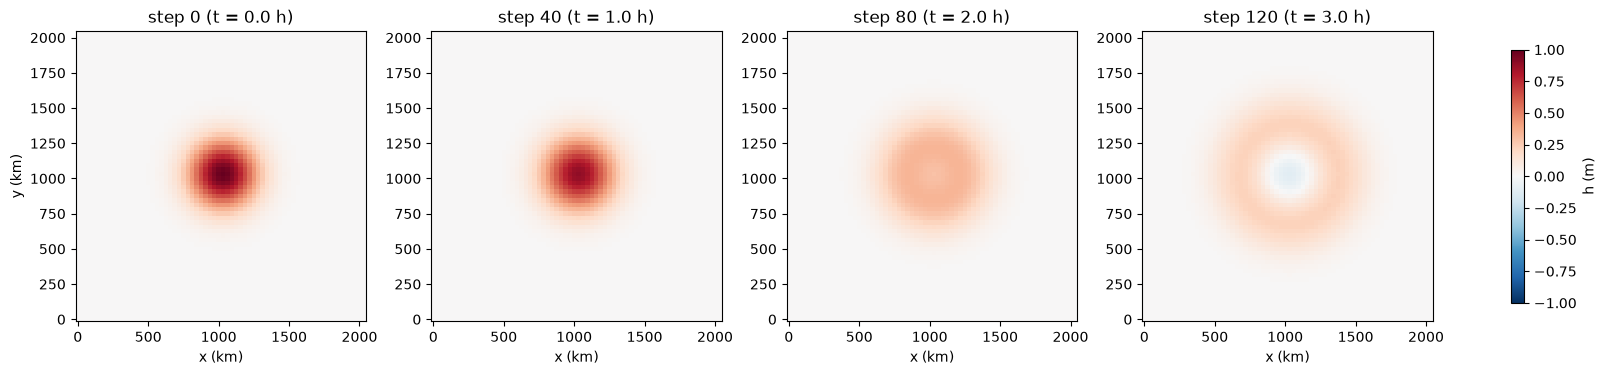

In [11]:
snapshots = [(0, initial_state)]
for index in [1, 3, 5]:
    carrier, _ = cycle.history[index]
    snapshots.append(((index + 1) * stride, carrier))

fig, axes = plt.subplots(
    1, len(snapshots), figsize=(4 * len(snapshots), 3.6), layout="constrained"
)
largest = float(jnp.max(jnp.abs(initial_height)))
for ax, (step_count, state) in zip(axes, snapshots, strict=True):
    mesh = ax.pcolormesh(
        x_grid / 1e3,
        y_grid / 1e3,
        state.h,
        cmap="RdBu_r",
        vmin=-largest,
        vmax=largest,
        shading="auto",
    )
    ax.set_title(f"step {step_count} (t = {step_count * time_step / 3600:.1f} h)")
    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (km)")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="h (m)")
plt.show()

## 7. Operators compose

Operators compose like any pipekit stage, so `operator | operator` is two steps. It matches two calls to the operator in turn.

In [12]:
# today (pipekit)
two_steps = (operator | operator)(initial_state)
# today (sesmax_core)
one_then_one = operator(operator(initial_state))
print(f"op | op is two steps: {bool(jnp.allclose(two_steps.h, one_then_one.h))}")

op | op is two steps: True


## 8. A gradient through the term tree

Because the coefficients in {eq}`composable-rhs` are leaves, `eqx.filter_grad` reaches them through the whole sum, here for the sum of squares of the height after ten steps. These coefficients are $\nu$ and the drag term's scale $-\kappa$, in that order.

In [13]:
# today (equinox)
@eqx.filter_grad
def height_gradient(model):
    """∂ℒ/∂(coefficients), for ℒ = ∑ h² after ten steps."""
    # today (sesmax_core)
    states = rollout(model, initial_state, dt=time_step, n_steps=10, save_every=10)
    # ℒ = ∑ h²
    return jnp.sum(states.h**2)


model_gradients = height_gradient(model)
coefficients = [
    term.coeff for term in model_gradients.terms.terms if hasattr(term, "coeff")
]
print(f"dL/d(viscosity coefficient): {float(coefficients[0]):.3e}")
print(f"dL/d(drag coefficient):      {float(coefficients[1]):.3e}")

dL/d(viscosity coefficient): 4.881e-08
dL/d(drag coefficient):      -7.387e+02


## Summary

| Concept | sesmax API |
| --- | --- |
| Terms | `Term`, `+`, `*`, `explicit`, `implicit`, `TermModel` |
| IMEX | `imex=True`, `imex_solver()`, `imex_stepsize_controller()` |
| A model as an operator | `ModelOp(model, dt=dt)` |
| A flat recipe as an operator | `Burgers2DOp(...)`, with `dumps` and `loads` |
| A host-side loop | `pipekit_cycle.Cycle(step_op=op, n_steps=n)` |
| A `jit`-native loop | `rollout(model, state, dt=dt, n_steps=n)` |

The same seams let the models plug into the data-assimilation libraries, by satisfying `ForwardModel` structurally: see [the ETKF page](data_assimilation_etkf.ipynb) and [the 4D-Var page](data_assimilation_4dvar.ipynb). The scenario registry in somax's version of this page moves with the ocean models in phase C2.